RELIABILITY ANALYSIS BY FORECAST DAY
Data path: /ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2020_2021/
Output path: ./verification_results/

1. Loading data...
   Found 177 files
   Loaded 10,868,520 matched pairs in 1.5 seconds
   Verification period: 2020-10-16 to 2021-04-10

2. Calculating reliability by forecast day...

   [ 1/7] Day 1 (0-21h) | BS: rain=0.0608, snow=0.0368, slee=0.0062
   [ 2/7] Day 2 (24-45h) | BS: rain=0.0610, snow=0.0367, slee=0.0056
   [ 3/7] Day 3 (48-69h) | BS: rain=0.0626, snow=0.0380, slee=0.0055
   [ 4/7] Day 4 (72-93h) | BS: rain=0.0652, snow=0.0396, slee=0.0054
   [ 5/7] Day 5 (96-117h) | BS: rain=0.0683, snow=0.0412, slee=0.0054
   [ 6/7] Day 6 (120-141h) | BS: rain=0.0710, snow=0.0424, slee=0.0054
   [ 7/7] Day 7 (144-168h) | BS: rain=0.0712, snow=0.0425, slee=0.0053

3. Summary statistics (Brier Score):

Type                 Mean BS    Min BS     Max BS     Valid Days  
---------------------------------------------------------------

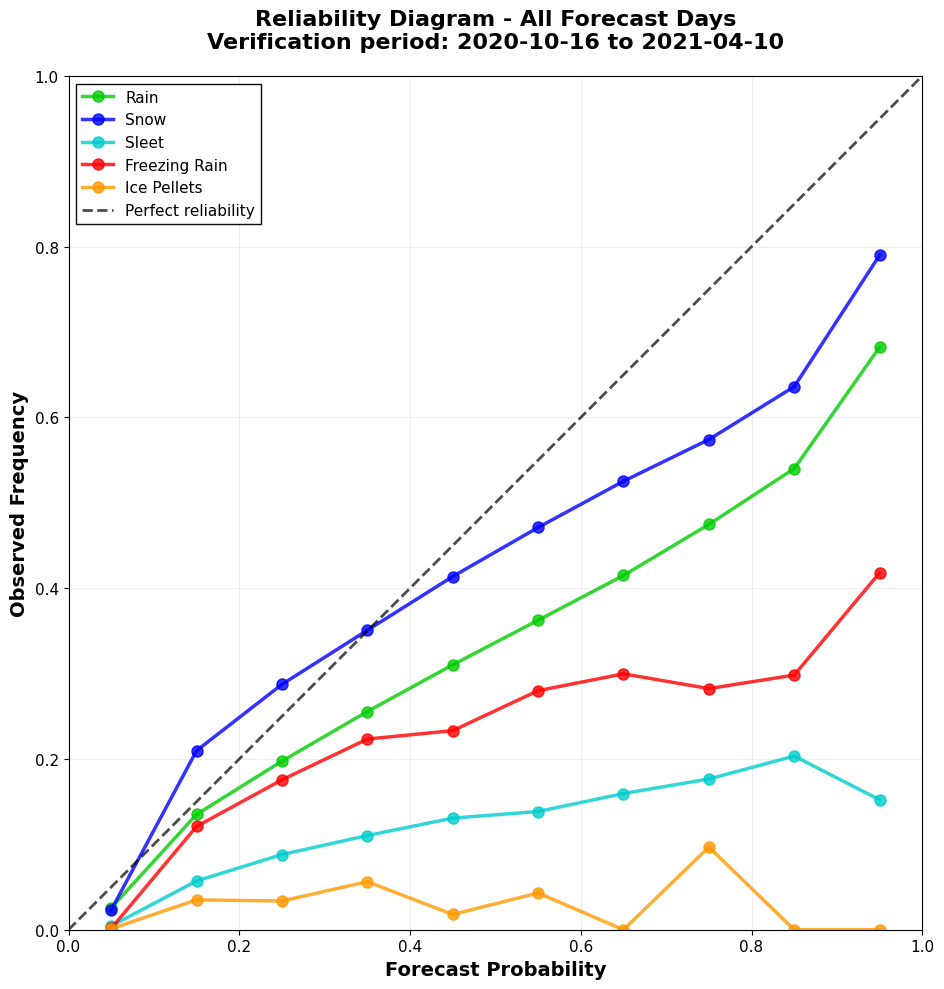

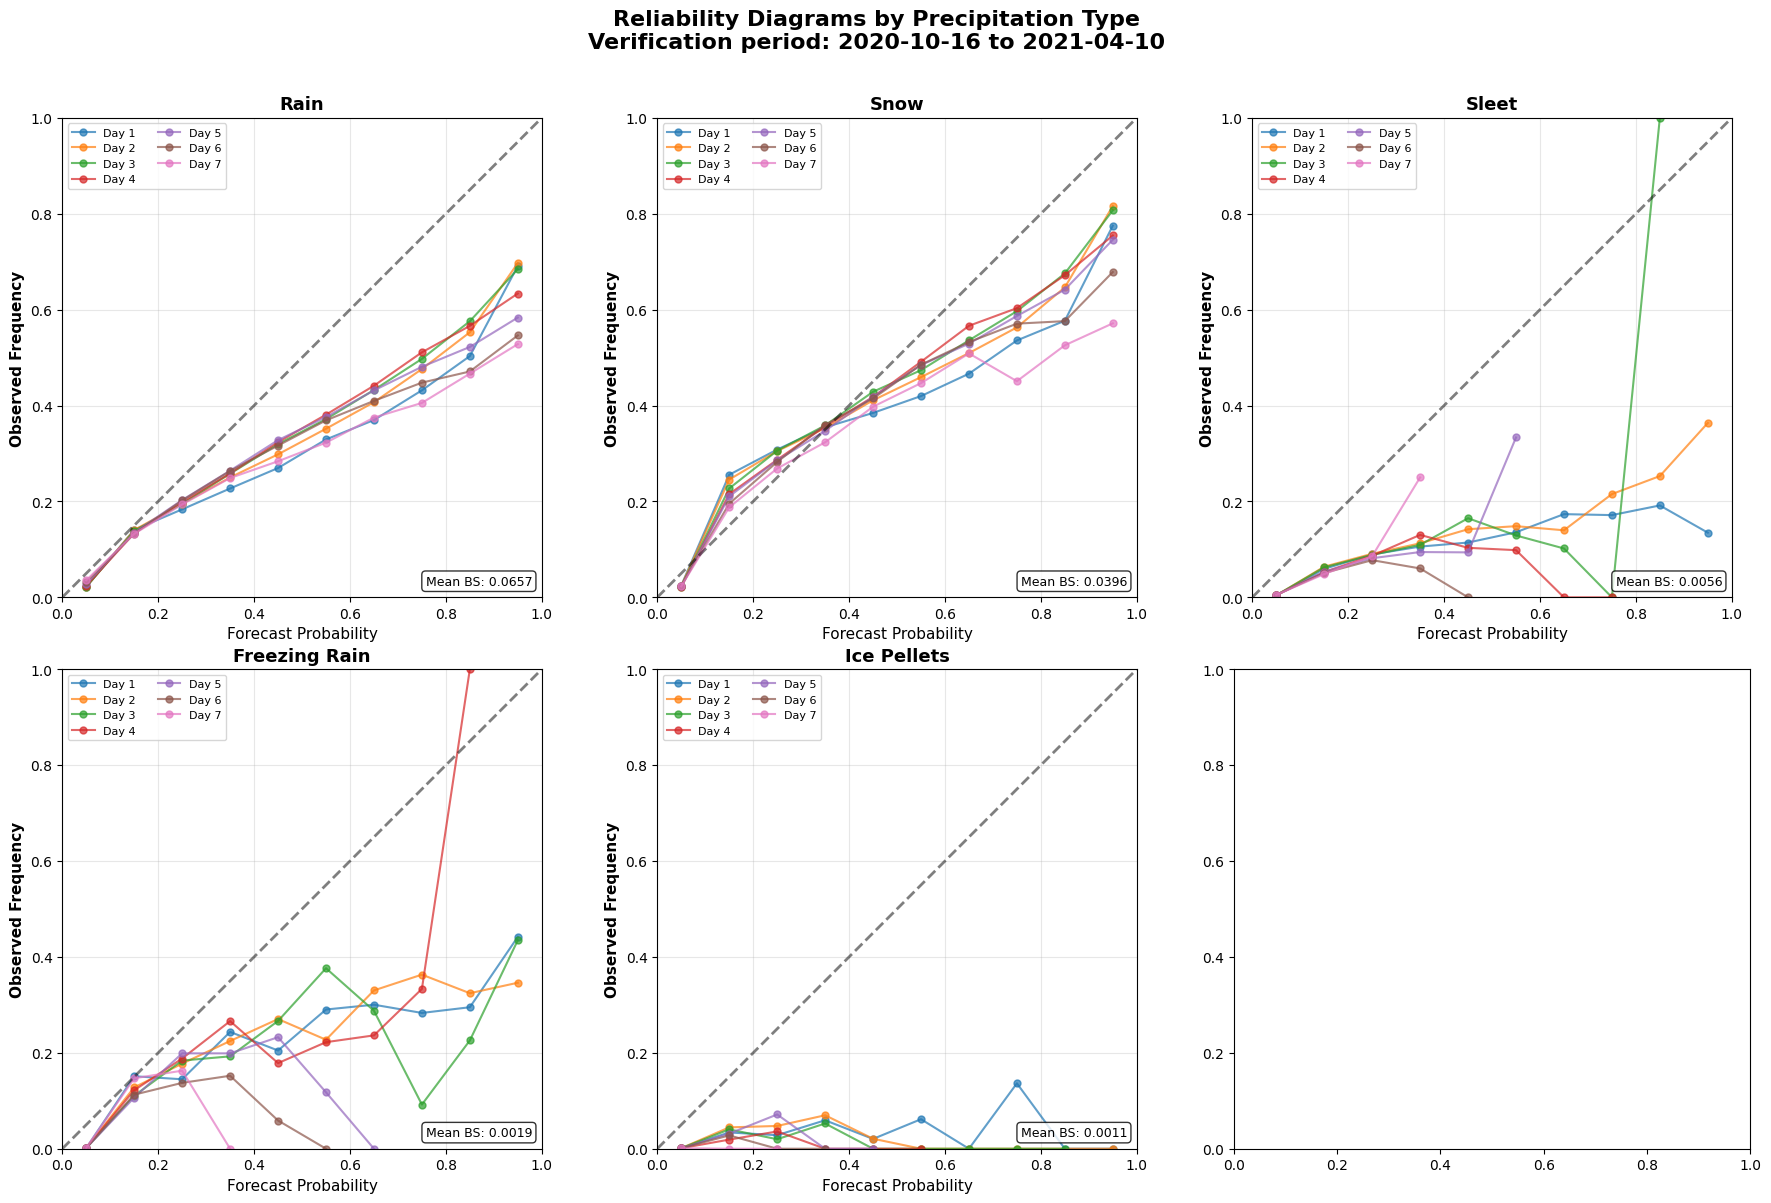

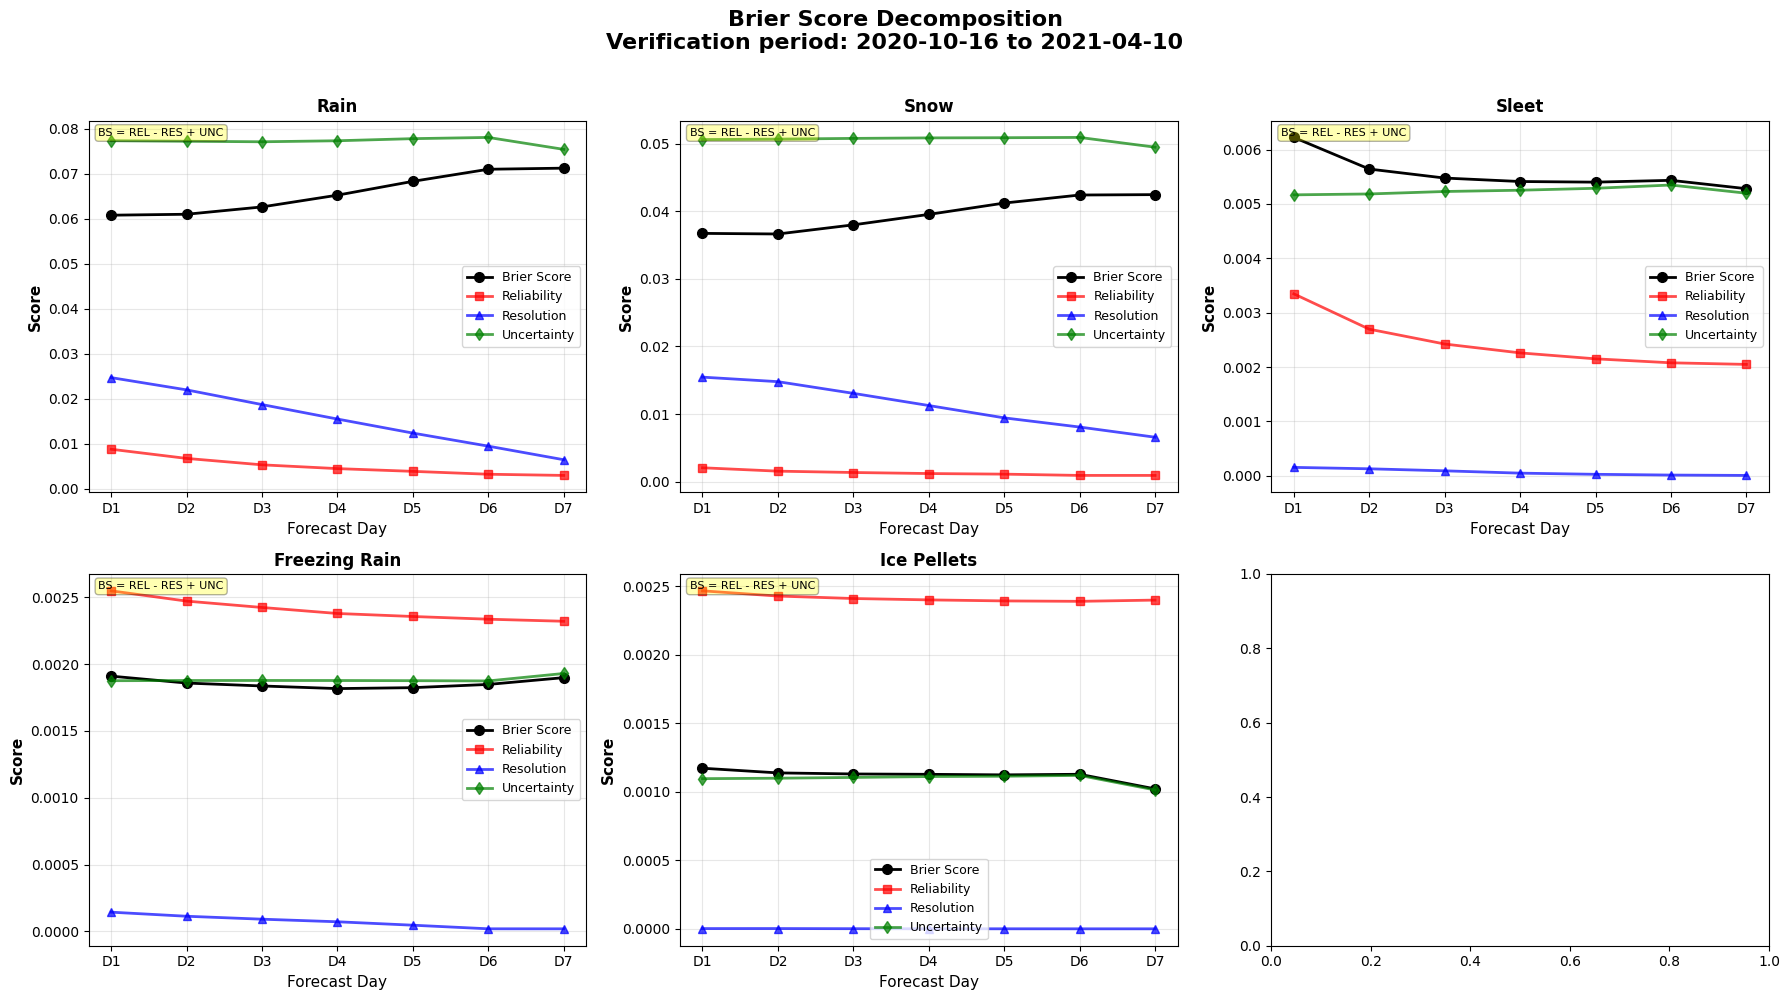

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss
import glob
from datetime import datetime
import os

#
# RELIABILITY ANALYSIS BY FORECAST DAY
# -------------------------------------
#
# Calculates reliability diagrams and metrics for probabilistic forecasts
# Shows how well forecast probabilities match observed frequencies
#
########################################

# ===== CONFIGURATION =====
DATA_PATH = "/ec/vol/enscal/VERIF_PrecipType/VERIF_ptype_all/DATA_preVerif/2020_2021/"
OUTPUT_PATH = "./verification_results/"

if not os.path.exists(OUTPUT_PATH):
    os.makedirs(OUTPUT_PATH, exist_ok=True)

PRECIP_TYPES = ['rain', 'snow', 'sleet', 'freezrain', 'icepellets']

COLORS = {
    'rain': '#00CC00',        # Bright green
    'snow': '#0000FF',        # Blue
    'sleet': '#00CCCC',       # Cyan/turquoise
    'freezrain': '#FF0000',   # Red
    'icepellets': '#FF9900'   # Orange
}

NICE_NAMES = {
    'rain': 'Rain',
    'snow': 'Snow',
    'sleet': 'Sleet',
    'freezrain': 'Freezing Rain',
    'icepellets': 'Ice Pellets'
}

# Probability bins for reliability diagram
PROB_BINS = np.arange(0, 101, 10)  # 0-10%, 10-20%, ..., 90-100%

print("="*70)
print("RELIABILITY ANALYSIS BY FORECAST DAY")
print("="*70)
print(f"Data path: {DATA_PATH}")
print(f"Output path: {OUTPUT_PATH}")
print()

# ===== LOAD DATA =====
print("1. Loading data...")
start_time = datetime.now()

files = sorted(glob.glob(DATA_PATH + "matched_pairs_*.parquet"))
print(f"   Found {len(files)} files")

if len(files) == 0:
    print("ERROR: No parquet files found!")
    exit(1)

df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

elapsed = (datetime.now() - start_time).total_seconds()
print(f"   Loaded {len(df):,} matched pairs in {elapsed:.1f} seconds")

# Extract verification period from data
start_date = df['forecast_date'].min()
end_date = df['forecast_date'].max()
# Convert to readable format (YYYYMMDD to YYYY-MM-DD)
start_date_str = f"{str(start_date)[:4]}-{str(start_date)[4:6]}-{str(start_date)[6:]}"
end_date_str = f"{str(end_date)[:4]}-{str(end_date)[4:6]}-{str(end_date)[6:]}"
period_str = f"Verification period: {start_date_str} to {end_date_str}"

print(f"   {period_str}")
print()

# ===== DEFINE DAY GROUPINGS =====
day_groups = {
    1: [0, 3, 6, 9, 12, 15, 18, 21],
    2: [24, 27, 30, 33, 36, 39, 42, 45],
    3: [48, 51, 54, 57, 60, 63, 66, 69],
    4: [72, 75, 78, 81, 84, 87, 90, 93],
    5: [96, 99, 102, 105, 108, 111, 114, 117],
    6: [120, 123, 126, 129, 132, 135, 138, 141],
    7: [144, 150, 156, 162, 168]
}

days = sorted(day_groups.keys())

print(f"2. Calculating reliability by forecast day...")
print()

# ===== CALCULATE RELIABILITY FOR EACH DAY =====
# Store reliability data: for each day and type, store (forecast_prob, observed_freq, sample_count)
reliability_data = {ptype: {day: {'bins': [], 'obs_freq': [], 'counts': []} 
                            for day in days} for ptype in PRECIP_TYPES}

# Store Brier Score and components
brier_scores = {ptype: [] for ptype in PRECIP_TYPES}
reliability_component = {ptype: [] for ptype in PRECIP_TYPES}
resolution_component = {ptype: [] for ptype in PRECIP_TYPES}
uncertainty_component = {ptype: [] for ptype in PRECIP_TYPES}

for day_idx, day in enumerate(days, start=1):
    
    steps_in_day = day_groups[day]
    step_range = f"{steps_in_day[0]}-{steps_in_day[-1]}h"
    
    print(f"   [{day_idx:2d}/{len(days)}] Day {day} ({step_range})", end='', flush=True)
    
    # Filter data for this day
    df_day = df[df['forecast_step'].isin(steps_in_day)]
    
    results_day = []
    
    for ptype in PRECIP_TYPES:
        
        obs_col = f'obs_{ptype}'
        prob_col = f'prob_{ptype}'
        
        # Get observations and probabilities
        obs = df_day[obs_col].values
        prob = df_day[prob_col].values
        
        # Remove NaN values
        valid_mask = ~np.isnan(prob)
        obs_valid = obs[valid_mask]
        prob_valid = prob[valid_mask]
        
        if len(obs_valid) == 0:
            results_day.append(f"{ptype[:4]}=NoData")
            brier_scores[ptype].append(np.nan)
            reliability_component[ptype].append(np.nan)
            resolution_component[ptype].append(np.nan)
            uncertainty_component[ptype].append(np.nan)
            continue
        
        # Calculate Brier Score
        prob_01 = prob_valid / 100.0  # Convert to [0,1]
        bs = brier_score_loss(obs_valid, prob_01)
        brier_scores[ptype].append(bs)
        
        # Calculate climatology (base rate)
        clim = obs_valid.mean()
        
        # Brier Score components
        # Uncertainty = o_bar * (1 - o_bar)
        uncertainty = clim * (1 - clim)
        uncertainty_component[ptype].append(uncertainty)
        
        # Calculate reliability curve (binned)
        bin_centers = []
        obs_freqs = []
        bin_counts = []
        
        for i in range(len(PROB_BINS) - 1):
            bin_start = PROB_BINS[i]
            bin_end = PROB_BINS[i + 1]
            bin_center = (bin_start + bin_end) / 2
            
            # Find forecasts in this bin
            mask = (prob_valid >= bin_start) & (prob_valid < bin_end)
            
            if i == len(PROB_BINS) - 2:  # Last bin includes upper boundary
                mask = (prob_valid >= bin_start) & (prob_valid <= bin_end)
            
            n_in_bin = mask.sum()
            
            if n_in_bin > 0:
                obs_freq = obs_valid[mask].mean()
                bin_centers.append(bin_center)
                obs_freqs.append(obs_freq)
                bin_counts.append(n_in_bin)
        
        # Store reliability data
        reliability_data[ptype][day]['bins'] = bin_centers
        reliability_data[ptype][day]['obs_freq'] = obs_freqs
        reliability_data[ptype][day]['counts'] = bin_counts
        
        # Calculate reliability component (REL)
        # REL = sum over bins of n_k * (f_k - o_k)^2 / N
        rel = 0
        for bc, of, cnt in zip(bin_centers, obs_freqs, bin_counts):
            rel += cnt * (bc/100.0 - of)**2
        rel = rel / len(obs_valid)
        reliability_component[ptype].append(rel)
        
        # Calculate resolution component (RES)
        # RES = sum over bins of n_k * (o_k - o_bar)^2 / N
        res = 0
        for of, cnt in zip(obs_freqs, bin_counts):
            res += cnt * (of - clim)**2
        res = res / len(obs_valid)
        resolution_component[ptype].append(res)
        
        results_day.append(f"{ptype[:4]}={bs:.4f}")
    
    print(f" | BS: {', '.join(results_day[:3])}")

print()

# ===== SUMMARY STATISTICS =====
print("3. Summary statistics (Brier Score):")
print()
print(f"{'Type':<20} {'Mean BS':<10} {'Min BS':<10} {'Max BS':<10} {'Valid Days':<12}")
print("-"*70)

for ptype in PRECIP_TYPES:
    bs_vals = np.array(brier_scores[ptype])
    valid_bs = bs_vals[~np.isnan(bs_vals)]
    
    if len(valid_bs) > 0:
        mean_bs = valid_bs.mean()
        min_bs = valid_bs.min()
        max_bs = valid_bs.max()
        n_valid = len(valid_bs)
    else:
        mean_bs = np.nan
        min_bs = np.nan
        max_bs = np.nan
        n_valid = 0
    
    print(f"{NICE_NAMES[ptype]:<20} {mean_bs:>8.4f}  {min_bs:>8.4f}  {max_bs:>8.4f}  {n_valid:>5d}/{len(days)}")

print()

# ===== CREATE RELIABILITY DIAGRAM (ALL TYPES COMBINED) =====
print("4. Creating combined reliability diagram...")

fig, ax = plt.subplots(figsize=(10, 10))

# Plot reliability curve for each precipitation type (averaged across all days)
for ptype in PRECIP_TYPES:
    
    # Aggregate across all days
    all_bins = []
    all_obs = []
    all_counts = []
    
    for day in days:
        bins = reliability_data[ptype][day]['bins']
        obs = reliability_data[ptype][day]['obs_freq']
        counts = reliability_data[ptype][day]['counts']
        
        all_bins.extend(bins)
        all_obs.extend(obs)
        all_counts.extend(counts)
    
    if len(all_bins) > 0:
        # Group by bins and calculate weighted average
        unique_bins = sorted(set(all_bins))
        bin_obs_freq = []
        
        for ub in unique_bins:
            # Find all observations for this bin
            indices = [i for i, b in enumerate(all_bins) if b == ub]
            total_count = sum([all_counts[i] for i in indices])
            weighted_obs = sum([all_obs[i] * all_counts[i] for i in indices]) / total_count
            bin_obs_freq.append(weighted_obs)
        
        # Plot
        ax.plot([b/100 for b in unique_bins], bin_obs_freq, 
                marker='o', 
                linewidth=2.5, 
                markersize=8,
                label=NICE_NAMES[ptype],
                color=COLORS[ptype],
                alpha=0.8)

# Perfect reliability line (diagonal)
ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfect reliability', alpha=0.7)

# Formatting
ax.set_xlabel('Forecast Probability', fontsize=14, fontweight='bold')
ax.set_ylabel('Observed Frequency', fontsize=14, fontweight='bold')
ax.set_title(f'Reliability Diagram - All Forecast Days\n{period_str}', 
             fontsize=16, fontweight='bold', pad=20)

ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_aspect('equal')

# Grid
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
ax.set_axisbelow(True)

# Legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.95, 
          edgecolor='black', fancybox=False)

ax.tick_params(axis='both', labelsize=11)


plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'reliability_combined.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}reliability_combined.png")
print()

# ===== CREATE INDIVIDUAL RELIABILITY DIAGRAMS =====
print("5. Creating individual reliability diagrams...")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

# Add overall title with verification period
fig.suptitle(f'Reliability Diagrams by Precipitation Type\n{period_str}', 
             fontsize=16, fontweight='bold', y=0.995)

for idx, ptype in enumerate(PRECIP_TYPES):
    ax = axes[idx]
    
    # Plot reliability for each day
    for day in days:
        bins = reliability_data[ptype][day]['bins']
        obs = reliability_data[ptype][day]['obs_freq']
        
        if len(bins) > 0:
            ax.plot([b/100 for b in bins], obs, 
                    marker='o', 
                    linewidth=1.5, 
                    markersize=5,
                    label=f'Day {day}',
                    alpha=0.7)
    
    # Perfect reliability line
    ax.plot([0, 1], [0, 1], 'k--', linewidth=2, alpha=0.5)
    
    # Formatting
    ax.set_xlabel('Forecast Probability', fontsize=11)
    ax.set_ylabel('Observed Frequency', fontsize=11, fontweight='bold')
    ax.set_title(NICE_NAMES[ptype], fontsize=13, fontweight='bold')
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left', fontsize=8, ncol=2)
    
    # Show mean Brier Score
    bs_vals = np.array(brier_scores[ptype])
    valid_bs = bs_vals[~np.isnan(bs_vals)]
    if len(valid_bs) > 0:
        mean_bs = valid_bs.mean()
        ax.text(0.98, 0.02, f'Mean BS: {mean_bs:.4f}', 
                transform=ax.transAxes, fontsize=9,
                verticalalignment='bottom', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout(rect=[0, 0, 1, 0.98])  # Leave space for suptitle
plt.savefig(OUTPUT_PATH + 'reliability_individual.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}reliability_individual.png")
print()

# ===== CREATE BRIER SCORE DECOMPOSITION PLOT =====
print("6. Creating Brier Score decomposition plot...")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Add overall title with verification period
fig.suptitle(f'Brier Score Decomposition\n{period_str}', 
             fontsize=16, fontweight='bold', y=0.995)

for idx, ptype in enumerate(PRECIP_TYPES):
    ax = axes[idx]
    
    bs_vals = np.array(brier_scores[ptype])
    rel_vals = np.array(reliability_component[ptype])
    res_vals = np.array(resolution_component[ptype])
    unc_vals = np.array(uncertainty_component[ptype])
    
    # Plot components
    ax.plot(days, bs_vals, marker='o', linewidth=2, markersize=7, 
            label='Brier Score', color='black')
    ax.plot(days, rel_vals, marker='s', linewidth=2, markersize=6, 
            label='Reliability', color='red', alpha=0.7)
    ax.plot(days, res_vals, marker='^', linewidth=2, markersize=6, 
            label='Resolution', color='blue', alpha=0.7)
    ax.plot(days, unc_vals, marker='d', linewidth=2, markersize=6, 
            label='Uncertainty', color='green', alpha=0.7)
    
    ax.set_xlabel('Forecast Day', fontsize=11)
    ax.set_ylabel('Score', fontsize=11, fontweight='bold')
    ax.set_title(f'{NICE_NAMES[ptype]}', fontsize=12, fontweight='bold')
    ax.set_xticks(days)
    ax.set_xticklabels([f'D{d}' for d in days])
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=9)
    
    # Add equation
    ax.text(0.02, 0.98, 'BS = REL - RES + UNC', 
            transform=ax.transAxes, fontsize=8,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.3))

plt.tight_layout(rect=[0, 0, 1, 0.98])  # Leave space for suptitle
plt.savefig(OUTPUT_PATH + 'brier_decomposition.png', dpi=300, bbox_inches='tight')
print(f"   Saved: {OUTPUT_PATH}brier_decomposition.png")
print()

# ===== SAVE RESULTS TO CSV =====
print("7. Saving results to CSV...")

# Brier Score results
bs_df = pd.DataFrame({
    'forecast_day': days,
    'step_range': [f"{day_groups[d][0]}-{day_groups[d][-1]}h" for d in days]
})

for ptype in PRECIP_TYPES:
    bs_df[f'bs_{ptype}'] = brier_scores[ptype]
    bs_df[f'rel_{ptype}'] = reliability_component[ptype]
    bs_df[f'res_{ptype}'] = resolution_component[ptype]
    bs_df[f'unc_{ptype}'] = uncertainty_component[ptype]

bs_df.to_csv(OUTPUT_PATH + 'brier_scores_by_day.csv', index=False)
print(f"   Saved: {OUTPUT_PATH}brier_scores_by_day.csv")
print()

# ===== FINAL SUMMARY =====
total_elapsed = (datetime.now() - start_time).total_seconds()

print("="*70)
print("ANALYSIS COMPLETE!")
print("="*70)
print(f"Total time: {total_elapsed:.1f} seconds")
print()
print("Output files:")
print(f"  - {OUTPUT_PATH}reliability_combined.png")
print(f"  - {OUTPUT_PATH}reliability_individual.png")
print(f"  - {OUTPUT_PATH}brier_decomposition.png")
print(f"  - {OUTPUT_PATH}brier_scores_by_day.csv")
print()

print("Key findings (Mean Brier Score):")
print()
for ptype in PRECIP_TYPES:
    bs_vals = np.array(brier_scores[ptype])
    valid_bs = bs_vals[~np.isnan(bs_vals)]
    
    if len(valid_bs) > 0:
        mean_bs = valid_bs.mean()
        
        # Classify
        if mean_bs < 0.01:
            quality = "Excellent"
        elif mean_bs < 0.05:
            quality = "Good"
        elif mean_bs < 0.10:
            quality = "Fair"
        else:
            quality = "Poor"
        
        print(f"  {NICE_NAMES[ptype]:<20}: Mean BS = {mean_bs:.4f} ({quality})")

print()
print("Interpretation:")
print("  Brier Score: Lower is better (0 = perfect)")
print("  Reliability Diagram: Points on diagonal = perfect calibration")
print("  Above diagonal = underforecasting (too low probabilities)")
print("  Below diagonal = overforecasting (too high probabilities)")
print()
print("  BS = Reliability - Resolution + Uncertainty")
print("    Reliability: Calibration error (lower is better)")
print("    Resolution: Ability to distinguish events (higher is better)")
print("    Uncertainty: Inherent unpredictability (depends on climate)")